# Chlorination with a neighbour NAC

[← All examples](../paper_examples.ipynb) · [Python analysis](../../tutorials/chlorination_analysis.py) · [Model inputs](../../src/mfobs/models/chlorination/inputs.py)

Compare the same chlorination rule with and without its neighbour condition. The graph family has an arbitrary finite alkyl tail; the generated event model closes in both variants.


<nav class="example-sections" aria-label="Example sections" style="display:flex;align-items:stretch;gap:5px;flex-wrap:wrap;margin:16px auto;padding-top:8px;padding-bottom:8px;border-bottom:1px solid #cddce1"><span data-topic="rules" style="background:#e7f3e9;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=nac-rules-query" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">1 · Rules &amp; state space</a></span><span data-topic="inputs" style="background:#fbe9e9;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=nac-rules-query" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">2 · Inputs &amp; semantics</a></span><span data-topic="observables" style="background:#e8f0fb;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=section-nav-b2c2f115" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">3 · Observable discovery</a></span><span data-topic="ode" style="background:#f0eafb;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap">4 · <span aria-disabled="true" title="Not derived" style="color:#737d83;display:inline-block;vertical-align:top">ODE<small style="display:block;font-size:10px;font-weight:400">Not derived</small></span> &amp; <a href="#cell-id=section-nav-0c2e5456" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">pJC</a></span><span data-topic="initial" style="background:#e3f3f0;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=430082e7" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">5 · Initial states</a></span><span data-topic="dynamics" style="background:#fff0de;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=section-nav-d38c9bf8" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">6 · Dynamics</a></span></nav>

In [1]:
from pathlib import Path
import sys
PACKAGE = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/mfobs').is_dir()))
sys.path[:0] = [str(PACKAGE / 'notebooks'), str(PACKAGE / 'src'), str(PACKAGE)]
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import visual_view as visual


## Rules and query

All five ring bonds stay aromatic (`:`). The two chlorination rules differ only in the NAC. The query Z counts ring chlorines.


In [2]:
from mfobs import ModelInputs, analyze
from mfobs.applications import Chlorination

backends = {v: Chlorination(v) for v in ("guarded", "ablated")}
defaults = {v: backend.specification() for v, backend in backends.items()}
Omega = defaults["guarded"].omega
rules = {v: model.rules for v, model in defaults.items()}
observables = defaults["guarded"].observables
inputs = {v: ModelInputs(Omega, rules[v], observables) for v in backends}
from mfobs.visual_links import editor_url
from IPython.display import Markdown, display

links = []
for variant, model in inputs.items():
    for name, gml in model.rule_gmls().items():
        if variant == "ablated" and name == "grow":
            continue
        label = "Tail growth" if name == "grow" else (
            "With NAC" if variant == "guarded" else "Without NAC")
        links.append(f"[{label}]({editor_url(gml)})")
for name, gml in inputs["guarded"].query_gmls().items():
    links.append(f"[Query {name}]({editor_url(gml)})")
display(Markdown(" · ".join(links)))


[With NAC](https://molfoundry.de/rule-editor?gml=rule%20%5B%0A%09ruleID%20%22single-chlorination-neighbour-Cl-NAC%22%0A%09left%20%5B%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%203%20label%20%22-%22%20%5D%0A%09%5D%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22H%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22H%22%20%5D%0A%09%09node%20%5B%20id%203%20label%20%22Cl%22%20%5D%0A%09%5D%0A%09right%20%5B%0A%09%09edge%20%5B%20source%200%20target%203%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%201%20target%202%20label%20%22-%22%20%5D%0A%09%5D%0A%09constrainAdj%20%5B%0A%09%09id%200%0A%09%09op%20%22%3D%22%0A%09%09count%202%0A%09%09nodeLabels%20%5B%20label%20%22C%22%20label%20%22C-%22%20%5D%0A%09%09edgeLabels%20%5B%20label%20%22%3A%22%20%5D%0A%09%5D%0A%09condition%20%5B%0A%09%09not%20%5B%0A%09%09%09exists%20%5B%0A%09%09%09%09node%20%5B%20id%204%20label%20%22C%22%20%5D%0A%09%09%09%09node%20%5B%20id%205%20label%20%22Cl%22%20%5D%0A%09%09%09%09edge%20%5B%20source%200%20target%204%20label%20%22%3A%22%20%5D%0A%09%09%09%09edge%20%5B%20source%204%20target%205%20label%20%22-%22%20%5D%0A%09%09%09%5D%0A%09%09%5D%0A%09%5D%0A%5D) · [Tail growth](https://molfoundry.de/rule-editor?gml=rule%20%5B%0A%09ruleID%20%22cp-terminal-methane-homologation-net-channel%22%0A%09left%20%5B%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%203%20label%20%22-%22%20%5D%0A%09%5D%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22H%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%203%20label%20%22H%22%20%5D%0A%09%09node%20%5B%20id%204%20label%20%22H%22%20%5D%0A%09%09node%20%5B%20id%205%20label%20%22H%22%20%5D%0A%09%09node%20%5B%20id%206%20label%20%22H%22%20%5D%0A%09%09node%20%5B%20id%207%20label%20%22H%22%20%5D%0A%09%09node%20%5B%20id%208%20label%20%22H%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%207%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%208%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%204%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%205%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%206%20label%20%22-%22%20%5D%0A%09%5D%0A%09right%20%5B%0A%09%09edge%20%5B%20source%200%20target%202%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%201%20target%203%20label%20%22-%22%20%5D%0A%09%5D%0A%09constrainAdj%20%5B%0A%09%09id%200%0A%09%09op%20%22%3D%22%0A%09%09count%201%0A%09%09nodeLabels%20%5B%20label%20%22C%22%20label%20%22C-%22%20%5D%0A%09%09edgeLabels%20%5B%20label%20%22-%22%20%5D%0A%09%5D%0A%5D) · [Without NAC](https://molfoundry.de/rule-editor?gml=rule%20%5B%0A%09ruleID%20%22single-chlorination-neighbour-Cl-NAC%22%0A%09left%20%5B%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%202%20target%203%20label%20%22-%22%20%5D%0A%09%5D%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22H%22%20%5D%0A%09%09node%20%5B%20id%202%20label%20%22H%22%20%5D%0A%09%09node%20%5B%20id%203%20label%20%22Cl%22%20%5D%0A%09%5D%0A%09right%20%5B%0A%09%09edge%20%5B%20source%200%20target%203%20label%20%22-%22%20%5D%0A%09%09edge%20%5B%20source%201%20target%202%20label%20%22-%22%20%5D%0A%09%5D%0A%09constrainAdj%20%5B%0A%09%09id%200%0A%09%09op%20%22%3D%22%0A%09%09count%202%0A%09%09nodeLabels%20%5B%20label%20%22C%22%20label%20%22C-%22%20%5D%0A%09%09edgeLabels%20%5B%20label%20%22%3A%22%20%5D%0A%09%5D%0A%5D) · [Query Z](https://molfoundry.de/rule-editor?gml=rule%20%5B%0A%09ruleID%20%22Z%22%0A%09context%20%5B%0A%09%09node%20%5B%20id%200%20label%20%22C%22%20%5D%0A%09%09node%20%5B%20id%201%20label%20%22Cl%22%20%5D%0A%09%09edge%20%5B%20source%200%20target%201%20label%20%22-%22%20%5D%0A%09%5D%0A%5D)

<p><strong style="background:#e8f0fb;padding:4px 8px;border-radius:4px">3 · Observable discovery</strong></p>

In [3]:
results = {v: analyze(model, backend=backends[v]).record() for v, model in inputs.items()}
visual.table([
    {"Rule": "With NAC" if v == "guarded" else "Without NAC",
     "Counts": ", ".join(r["pjc"]["coordinates"]),
     "pJC": r["pjc"]["status"], "Events": len(r["events"])}
    for v, r in results.items()
])


,Rule,Counts,pJC,Events
0,With NAC,"Z, P1, P2, P3",CLOSED_FINITE_EVENT_MODEL,4
1,Without NAC,Z,CLOSED_FINITE_EVENT_MODEL,1


<p><strong style="background:#f0eafb;padding:4px 8px;border-radius:4px">4 · pJC</strong></p>

In [4]:
for variant, result in results.items():
    print("With NAC" if variant == "guarded" else "Without NAC")
    visual.table([{"Rate / κ": event["activity"]["text"],
                   "Jump": ", ".join(f"Δ{name}={value:+d}" for name, value in event["delta"].items())}
                  for event in result["events"]])


With NAC


,Rate / κ,Jump
0,-P3*Z + 4*P3,"ΔZ=+1, ΔP1=-1, ΔP2=-2, ΔP3=-2"
1,-P3*Z + 4*P3,"ΔZ=+1, ΔP1=-1, ΔP2=-1, ΔP3=-2"
2,-2*P2*Z + 8*P2 + 2*P3*Z - 8*P3,"ΔZ=+1, ΔP1=-1, ΔP2=-1"
3,-P1*Z + 4*P1 + P2*Z - 4*P2,"ΔZ=+1, ΔP1=-1"


Without NAC


,Rate / κ,Jump
0,Z**2 - 8*Z + 16,ΔZ=+1


## 5 · Initial states

`INITIAL_MASK=0` starts unchlorinated; `1` starts with one chlorine, `9` with chlorine at sites 1 and 4. The curves integrate the finite forward equations of the generated event model. Tail growth has zero jump on these counts.


In [5]:
INITIAL_MASK = 0  # also try 1 or 9
RATE = 1.
T = 3.

<p><strong style="background:#fff0de;padding:4px 8px;border-radius:4px">6 · Dynamics</strong></p>

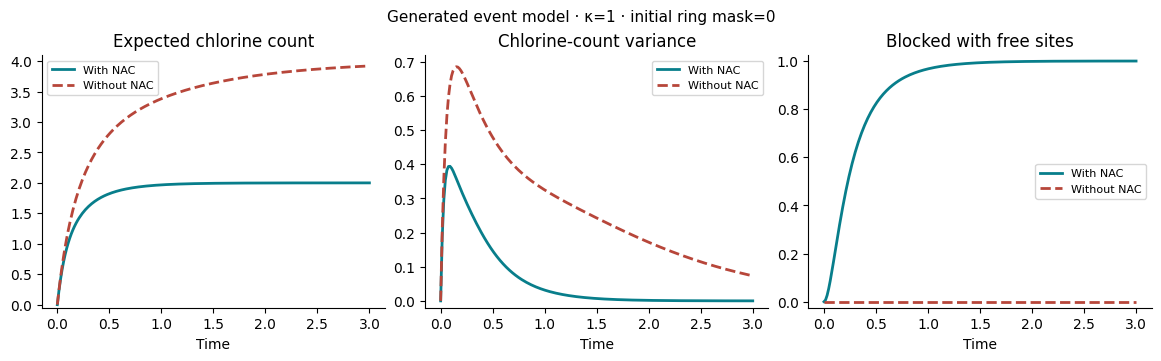

Run All in JupyterLab to activate the sliders.

In [6]:
visual.close_controls(globals().get("controls"))
curves = visual.show_curve(visual.context_nac_curve(results, mask=INITIAL_MASK, rate=RATE, end=T))
controls = visual.context_nac_sliders(results, curves, mask=INITIAL_MASK, rate=RATE, end=T)

[← All examples](../paper_examples.ipynb)